# **PRAKTIKUM 1**

### **Langkah 1 - Import Library**

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### **Langkah 2 - Baca Data**

In [2]:
data = pd.read_csv('../Data/jakarta_house.csv')
data['building_area'] = data['building_area'].fillna(data['building_area'].mean())
data['land_area'] = data['land_area'].fillna(data['land_area'].mean())

### **Langkah 3 - Pemahaman Terhadap Data**

In [3]:
# melihat beberapa data awal
data.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


In [4]:
# mengecek ukuran data
data.shape

(10000, 9)

In [5]:
# informasi tentang data
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  str    
 3   city           10000 non-null  str    
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      10000 non-null  float64
 8   building_area  10000 non-null  float64
dtypes: float64(2), int64(5), str(2)
memory usage: 937.6 KB


In [6]:
# deskripsi data
data.describe()

,index,price,bed_rooms,bath_rooms,carport,land_area,building_area
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.004029e+10,4.253500,3.521300,1.578900,296.610183,319.962481
std,2886.89568,2.004519e+10,3.176609,2.900136,1.743467,502.846235,357.586595
min,1.00000,1.850000e+06,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2500.75000,2.500000e+09,3.000000,2.000000,1.000000,100.000000,139.000000
50%,5000.50000,4.500000e+09,4.000000,3.000000,1.000000,177.000000,230.000000
75%,7500.25000,9.800000e+09,5.000000,4.000000,2.000000,335.000000,400.000000
max,10000.00000,9.000000e+11,63.000000,63.000000,31.000000,17714.000000,15331.000000


### **Langkah 4 - Visualisasi Data**

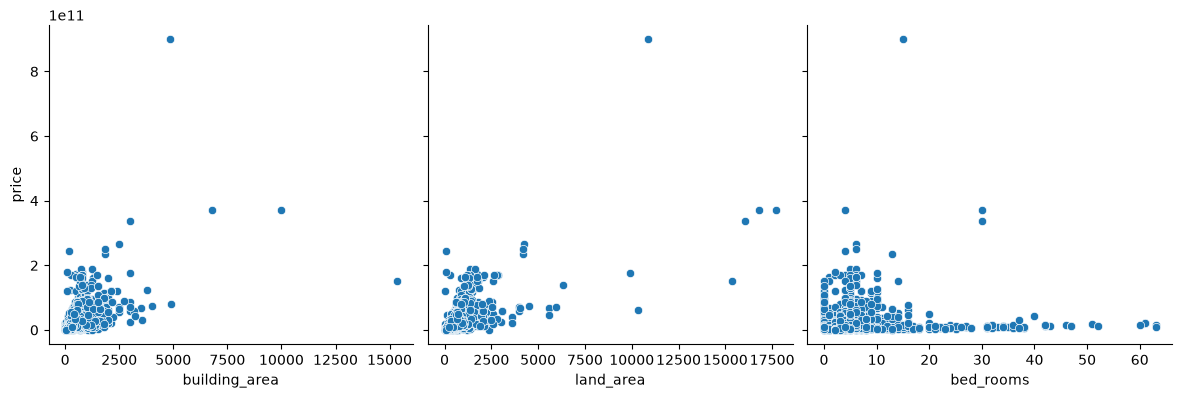

In [7]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['building_area', 'land_area', 'bed_rooms'],
             y_vars='price', size=4, aspect=1, kind='scatter')
plt.show()

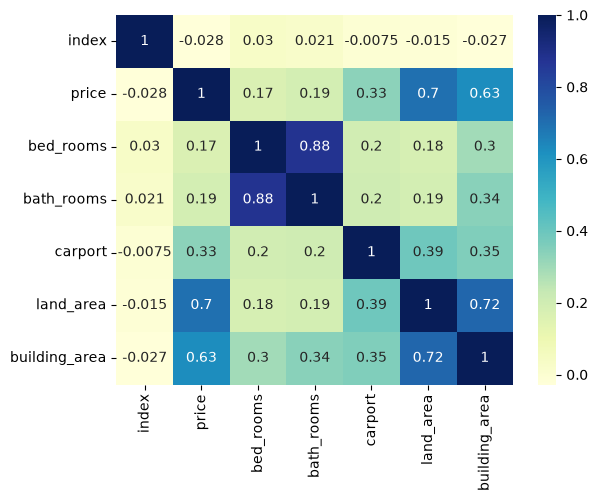

In [8]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

### **Langkah 5 - Regresi Linier**

In [9]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['building_area']
y = data['price']

In [10]:
# Pembagian data latih dan data uji dengan proporsi 7:3
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.7,
    test_size=0.3,
    random_state=100
    )

In [11]:
# Training model
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

In [12]:
# Melihat parameter model (intercept dan slope)
lr.params

const           -8.992386e+08
building_area    3.422743e+07
dtype: float64

In [13]:
# Menghitung parameter model secara manual
x_mean = X_train.mean()
y_mean = y_train.mean()

# Koefisien regresi (slope)
beta_1 = np.sum((X_train - x_mean) * (y_train - y_mean)) / np.sum((X_train - x_mean) ** 2)

# Intercept
beta_0 = y_mean - beta_1 * x_mean

In [14]:
# Membandingkan parameter hasil manual dengan hasil library (statsmodels)
print("Intercept (manual)  :", beta_0)
print("Intercept (library) :", lr.params['const'])
print()
print("Slope (manual)      :", beta_1)
print("Slope (library)     :", lr.params['building_area'])


Intercept (manual)  : -899238590.0709591
Intercept (library) : -899238590.0709652

Slope (manual)      : 34227431.06923904
Slope (library)     : 34227431.069239095


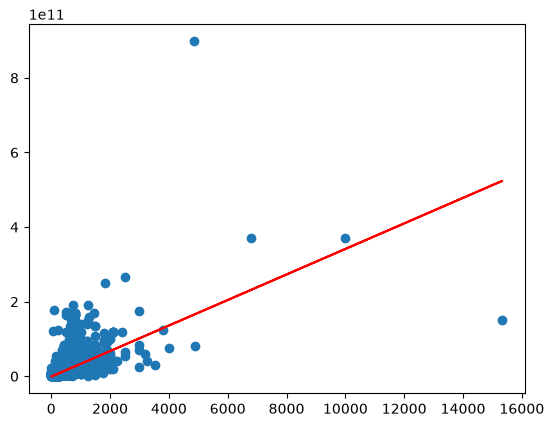

In [15]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, lr.params.iloc[0] + lr.params.iloc[1]*X_train, 'r')
plt.show()

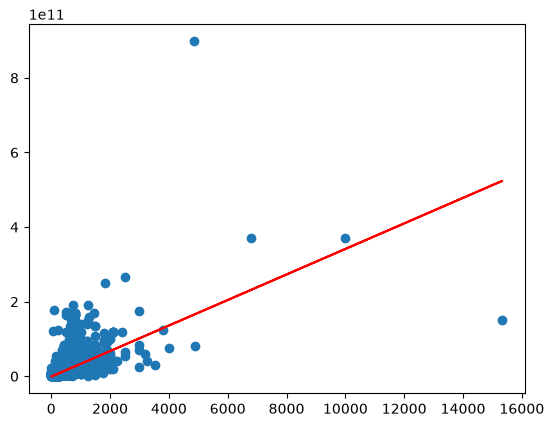

In [16]:
# Visualisasi garis regresi (memakai parameter hasil manual)
plt.scatter(X_train, y_train)
plt.plot(X_train, beta_0 + beta_1*X_train, 'r')
plt.show()

### **Langkah 6 - Analisis Residual**

In [17]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

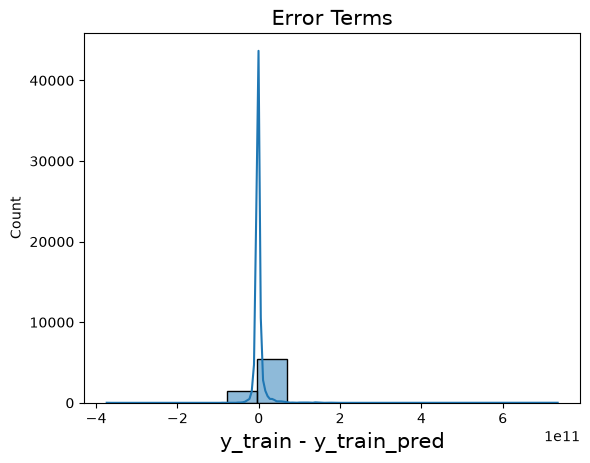

In [18]:
# Histogram residual
fig = plt.figure()
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

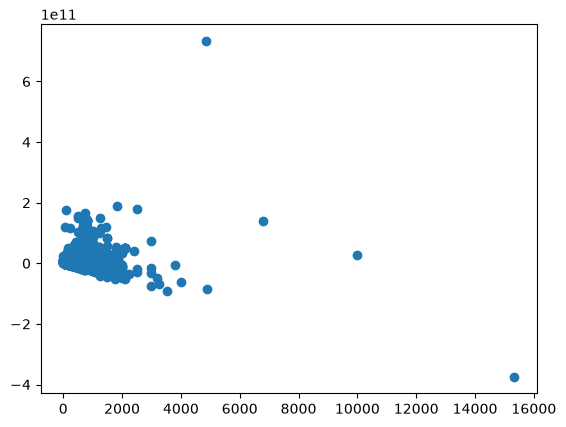

In [19]:
# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

In [20]:
# Prediksi nilai y dari data latih secara manual (memakai parameter hasil manual)
y_train_pred_manual = beta_0 + beta_1 * X_train

# Menghitung residual secara manual
res_manual = y_train - y_train_pred_manual

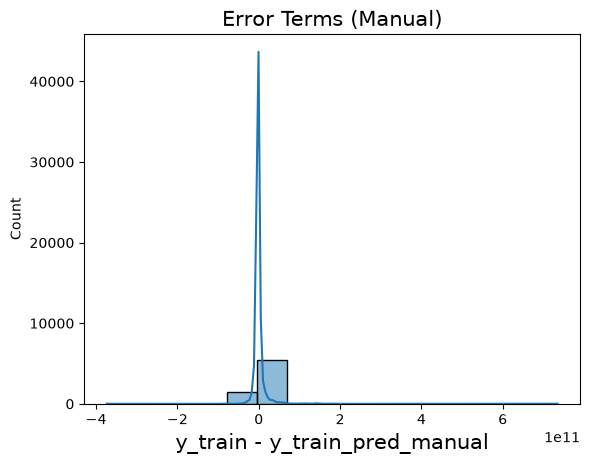

In [21]:
# Histogram residual manual
fig = plt.figure()
sns.histplot(res_manual, bins=15, kde=True)
plt.title('Error Terms (Manual)', fontsize=15)
plt.xlabel('y_train - y_train_pred_manual', fontsize=15)
plt.show()

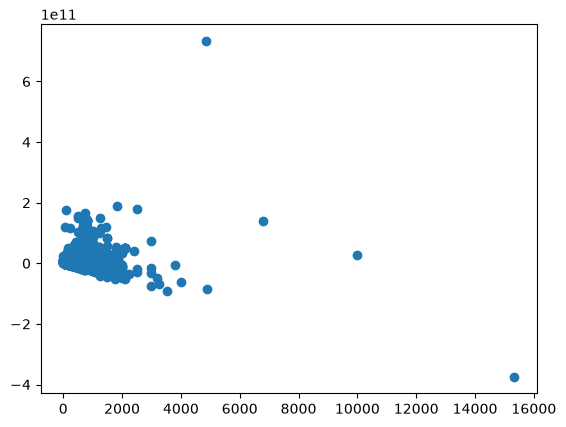

In [22]:
# Scatter plot residual manual
plt.scatter(X_train, res_manual)
plt.show()

In [23]:
# Membandingkan residual hasil manual dan library
print("Rata-rata residual (manual)  :", res_manual.mean())
print("Rata-rata residual (library) :", res.mean())

Rata-rata residual (manual)  : 1.2381417410714286e-06
Rata-rata residual (library) : -9.591238839285714e-06


### **Langkah 7 - Prediksi pada Data Uji dan Evaluasi Model**

In [24]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

In [25]:
# Prediksi pada data uji secara manual
y_manual_pred = beta_0 + beta_1 * X_test

In [26]:
# Hitung nilai R-squared, MAE, MSE, dan RMSE
r_squared = r2_score(y_test, y_test_pred)

mae = mean_absolute_error(y_test, y_test_pred)

mse = mean_squared_error(y_test, y_test_pred)

rmse = np.sqrt(mse)

In [27]:
# Hitung nilai R-squared, MAE, MSE, dan RMSE secara manual
RSS = np.sum((y_test - y_manual_pred) ** 2)
TSS = np.sum((y_test - np.mean(y_test)) ** 2)

r2_manual = 1 - (RSS / TSS)
mae_manual = np.mean(np.abs(y_test - y_manual_pred))
mse_manual = np.mean((y_test - y_manual_pred) ** 2)
rmse_manual = np.sqrt(mse_manual)

In [28]:
# Membandingkan hasil manual dan library
hasil = pd.DataFrame({
    'Manual': [r2_manual, mae_manual, mse_manual, rmse_manual],
    'Library': [r_squared, mae, mse, rmse]
}, index=['R-squared', 'MAE', 'MSE', 'RMSE'])

hasil

,Manual,Library
R-squared,4.156392e-01,4.156392e-01
MAE,5.260034e+09,5.260034e+09
MSE,1.724484e+20,1.724484e+20
RMSE,1.313196e+10,1.313196e+10


### **Langkah 8 - Visualisasi Hasil**

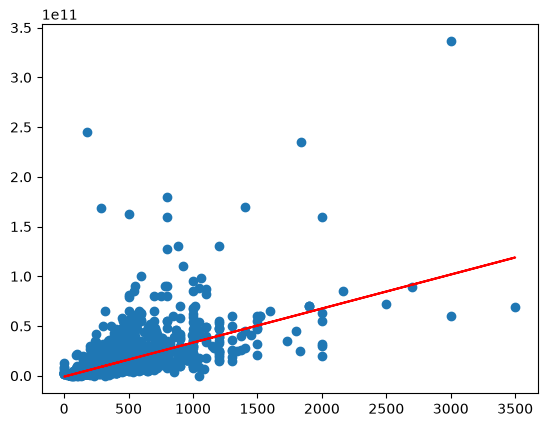

In [29]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

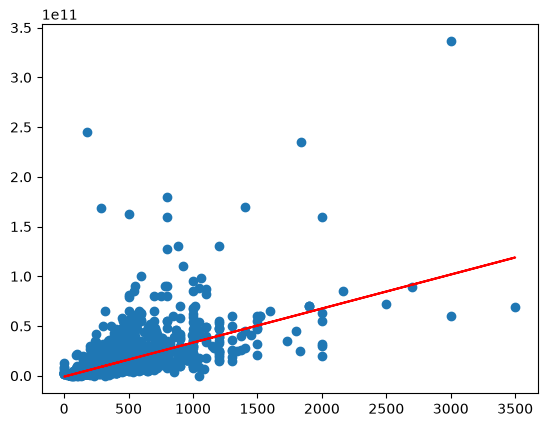

In [30]:
# Visualisasi data uji dan hasil prediksi manual
plt.scatter(X_test, y_test)
plt.plot(X_test, y_manual_pred, 'r')
plt.show()

# **PRAKTIKUM 2**

### **Langkah 1 - Import Library**

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### **Langkah 2 - Mengimpor Dataset**

In [32]:
dataset = pd.read_csv('../Data/jakarta_house.csv')
dataset['building_area'] = dataset['building_area'].fillna(dataset['building_area'].mean())
X = dataset[['building_area']].values
y = dataset['price'].values

### **Langkah 3 - Feature Scaling**

In [33]:
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

### **Langkah 4 - Fitting SVR ke Dataset**

In [34]:
regressor = SVR(kernel='rbf')
regressor.fit(X, y.ravel())

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


### **Langkah 5 - Visualisasi Hasil SVR**

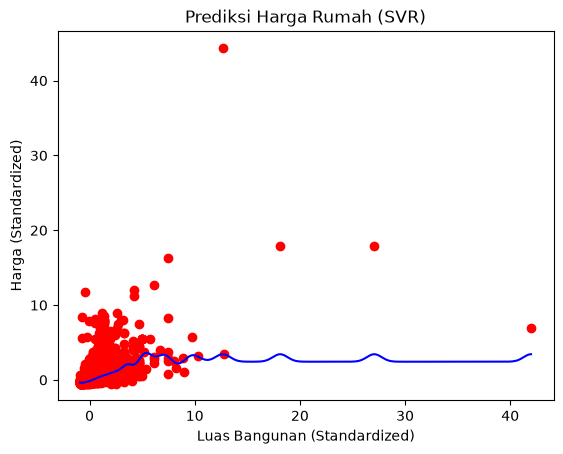

In [35]:
X_grid = np.arange(float(np.min(X)), float(np.max(X)), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Prediksi Harga Rumah (SVR)')
plt.xlabel('Luas Bangunan (Standardized)')
plt.ylabel('Harga (Standardized)')
plt.show()

### **Langkah 6 - Prediksi Hasil**

In [36]:
# Buat array 2D yang berisi luas bangunan yang akan diprediksi
luas_bangunan_prediksi = np.array([[200.0]])

# Penskalaan fitur untuk data yang akan diprediksi
luas_bangunan_prediksi = sc_X.transform(luas_bangunan_prediksi)

# Melakukan prediksi menggunakan model SVR
harga_prediksi = regressor.predict(luas_bangunan_prediksi)

# Kembalikan hasil prediksi ke skala aslinya
harga_prediksi = sc_y.inverse_transform(harga_prediksi.reshape(-1, 1))

### **Langkah 7 - Menampilkan Hasil**

In [37]:
print("Prediksi Harga untuk Luas Bangunan 200 m2:", harga_prediksi[0][0])

Prediksi Harga untuk Luas Bangunan 200 m2: 4436734997.4628525


### **Langkah 8 - Evaluasi Model SVR**

In [38]:
y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.25549261673874424
MSE: 0.663528697088435
RMSE: 0.8145727082884836
R-squared: 0.336471302911565
